# Analyse exploratoire du dataset

Ce notebook permet d'analyser en profondeur le contenu du dataset :
- Structure et statistiques générales
- Distribution des phrases VALID vs INVALID
- Analyse des villes et leurs fréquences
- Patterns de phrases et structures grammaticales
- Analyse des pièges (traps)
- Visualisations diverses

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
from collections import Counter, defaultdict
import json
import warnings
warnings.filterwarnings('ignore')

# Configuration des graphiques
plt.style.use('seaborn-v0_8')
sns.set_palette("husl")
%matplotlib inline

# Configuration pour pandas
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.max_colwidth', 80)

## 1. Chargement des données

In [2]:
def load_dataset():
    """Charge les fichiers d'entrée et de sortie du dataset"""
    # Charge les phrases d'entrée
    input_texts = []
    with open('./dataset/dataset_input.txt', 'r', encoding='utf-8') as f:
        for line in f:
            line = line.strip()
            if ',' in line:
                parts = line.split(',', 1)
                if len(parts) == 2 and parts[0].strip().isdigit():
                    input_texts.append(parts[1].strip())
                else:
                    input_texts.append(line)
            else:
                input_texts.append(line)
    
    # Charge les résultats attendus
    outputs = []
    with open('./dataset/dataset_output.txt', 'r', encoding='utf-8') as f:
        for line in f:
            line = line.strip()
            if ',' in line:
                parts = line.split(',')
                if len(parts) >= 3:
                    idx = parts[0]
                    depart = parts[1] if parts[1] else 'INVALID'
                    arrivee = parts[2] if len(parts) > 2 and parts[2] else 'INVALID'
                    outputs.append((depart, arrivee))
    
    # Crée un DataFrame
    df = pd.DataFrame({
        'phrase': input_texts,
        'depart': [d for d, _ in outputs],
        'arrivee': [a for _, a in outputs]
    })
    
    # Ajoute des colonnes dérivées
    df['is_valid'] = df['depart'] != 'INVALID'
    df['has_departure'] = df['depart'] != 'INVALID'
    df['has_arrival'] = df['arrivee'] != 'INVALID'
    df['phrase_length'] = df['phrase'].str.len()
    df['word_count'] = df['phrase'].str.split().str.len()
    
    return df

# Charge le dataset
print("📊 Chargement du dataset...")
df = load_dataset()
print(f"✅ Dataset chargé: {len(df)} phrases")
print(f"\nPremières lignes:")
print(df.head(10))

📊 Chargement du dataset...
✅ Dataset chargé: 11000 phrases

Premières lignes:
                                                       phrase       depart  \
0                                    je cherche un restaurant      INVALID   
1               y a-t-il des trains de limoges à villeurbanne      Limoges   
2       Un voyage de amiens a vitry-sur-seine s'il vous plait       Amiens   
3                  je voudrai aller de orléans à villeurbanne      Orléans   
4                                   de grenoble vers colombes     Grenoble   
5                             trains de valerie vers colombes      INVALID   
6                    je voudrais aller de rennes a strasbourg       Rennes   
7                       Avez-vous des trains de nancy à lille        Nancy   
8  je veux aller voir mon ami a amiens en partant de merignac     Mérignac   
9          je voudrai aller de montpellier à clermont-ferrand  Montpellier   

            arrivee  is_valid  has_departure  has_arrival  phra

## 2. Statistiques générales

In [3]:
print("=" * 80)
print("📈 STATISTIQUES GÉNÉRALES")
print("=" * 80)
print(f"\nTotal de phrases: {len(df):,}")
print(f"Phrases VALID: {df['is_valid'].sum():,} ({df['is_valid'].mean()*100:.1f}%)")
print(f"Phrases INVALID: {(~df['is_valid']).sum():,} ({(~df['is_valid']).mean()*100:.1f}%)")
print(f"\nLongueur moyenne des phrases: {df['phrase_length'].mean():.1f} caractères")
print(f"Nombre moyen de mots: {df['word_count'].mean():.1f} mots")
print(f"\nLongueur min: {df['phrase_length'].min()} caractères")
print(f"Longueur max: {df['phrase_length'].max()} caractères")
print(f"\nMots min: {df['word_count'].min()} mots")
print(f"Mots max: {df['word_count'].max()} mots")

📈 STATISTIQUES GÉNÉRALES

Total de phrases: 11,000
Phrases VALID: 9,000 (81.8%)
Phrases INVALID: 2,000 (18.2%)

Longueur moyenne des phrases: 40.9 caractères
Nombre moyen de mots: 7.2 mots

Longueur min: 9 caractères
Longueur max: 93 caractères

Mots min: 1 mots
Mots max: 17 mots


## 3. Distribution VALID vs INVALID

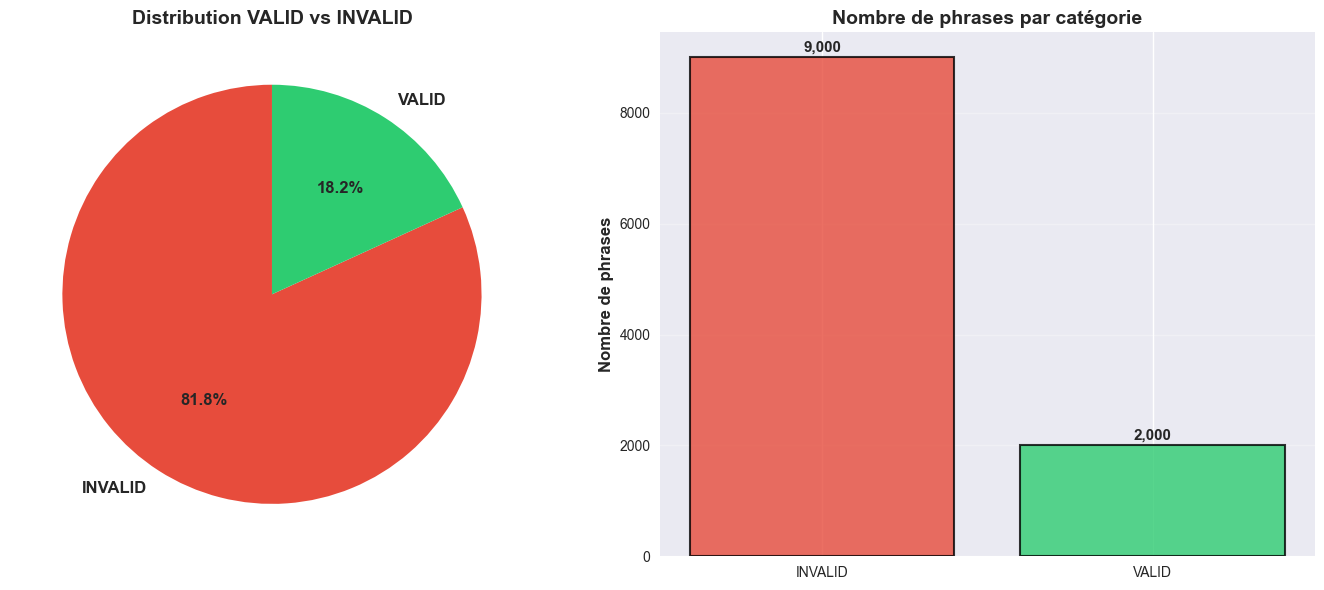

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Graphique en camembert
valid_counts = df['is_valid'].value_counts()
axes[0].pie(valid_counts.values, 
            labels=['INVALID', 'VALID'], 
            autopct='%1.1f%%',
            colors=['#e74c3c', '#2ecc71'],
            startangle=90,
            textprops={'fontsize': 12, 'fontweight': 'bold'})
axes[0].set_title('Distribution VALID vs INVALID', fontsize=14, fontweight='bold')

# Graphique en barres
bars = axes[1].bar(['INVALID', 'VALID'], valid_counts.values, 
                   color=['#e74c3c', '#2ecc71'], alpha=0.8, edgecolor='black', linewidth=1.5)
axes[1].set_ylabel('Nombre de phrases', fontsize=12, fontweight='bold')
axes[1].set_title('Nombre de phrases par catégorie', fontsize=14, fontweight='bold')
axes[1].grid(axis='y', alpha=0.3)

# Ajoute les valeurs sur les barres
for bar in bars:
    height = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2., height + 50,
                f'{int(height):,}',
                ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

## 4. Analyse des villes

In [5]:
# Extrait toutes les villes (départ et arrivée)
all_departures = df[df['depart'] != 'INVALID']['depart'].tolist()
all_arrivals = df[df['arrivee'] != 'INVALID']['arrivee'].tolist()
all_cities = all_departures + all_arrivals

city_counts = Counter(all_cities)
top_cities = city_counts.most_common(20)

print(f"🏙️  STATISTIQUES DES VILLES")
print(f"   {'-' * 50}")
print(f"   Villes uniques: {len(city_counts)}")
print(f"   Total d'occurrences: {len(all_cities)}")
print(f"\n   Top 10 des villes les plus fréquentes:")
for i, (city, count) in enumerate(top_cities[:10], 1):
    print(f"   {i:2d}. {city:25s} : {count:5d} fois ({count/len(all_cities)*100:5.2f}%)")

🏙️  STATISTIQUES DES VILLES
   --------------------------------------------------
   Villes uniques: 62
   Total d'occurrences: 18000

   Top 10 des villes les plus fréquentes:
    1. Saint-Denis               :   563 fois ( 3.13%)
    2. Toulon                    :   314 fois ( 1.74%)
    3. Reims                     :   313 fois ( 1.74%)
    4. Angers                    :   313 fois ( 1.74%)
    5. Vitry-sur-Seine           :   310 fois ( 1.72%)
    6. Villeurbanne              :   306 fois ( 1.70%)
    7. Tours                     :   305 fois ( 1.69%)
    8. Amiens                    :   304 fois ( 1.69%)
    9. Rennes                    :   304 fois ( 1.69%)
   10. Lourdes                   :   302 fois ( 1.68%)


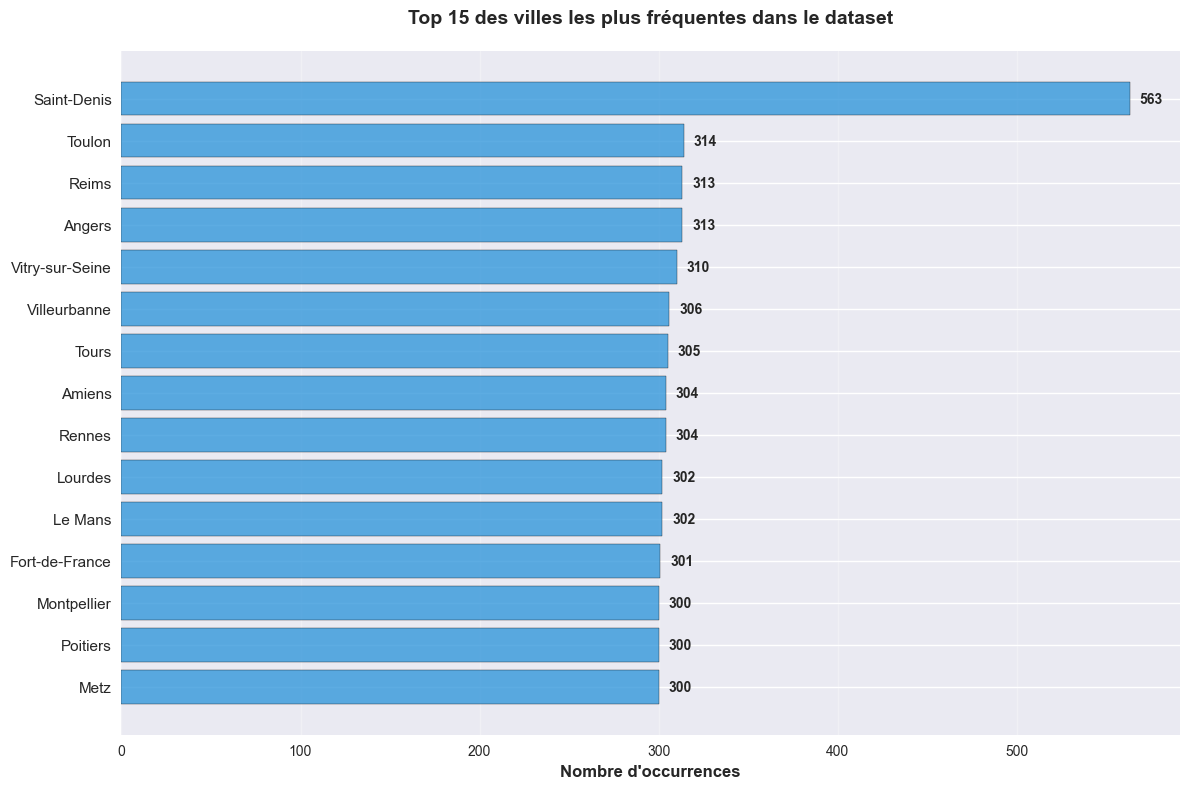

In [6]:
# Graphique des villes les plus fréquentes
fig, ax = plt.subplots(1, 1, figsize=(12, 8))
cities, counts = zip(*top_cities[:15])
bars = ax.barh(range(len(cities)), counts, color='#3498db', alpha=0.8, edgecolor='black')
ax.set_yticks(range(len(cities)))
ax.set_yticklabels(cities, fontsize=11)
ax.set_xlabel('Nombre d\'occurrences', fontsize=12, fontweight='bold')
ax.set_title('Top 15 des villes les plus fréquentes dans le dataset', fontsize=14, fontweight='bold', pad=20)
ax.invert_yaxis()
ax.grid(axis='x', alpha=0.3)

# Ajoute les valeurs
for i, (bar, count) in enumerate(zip(bars, counts)):
    ax.text(count + max(counts) * 0.01, bar.get_y() + bar.get_height()/2,
            str(count), va='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

In [7]:
# Analyse départ vs arrivée
departure_counts = Counter(all_departures)
arrival_counts = Counter(all_arrivals)

# Villes qui apparaissent plus souvent en départ qu'en arrivée
departure_only = set(departure_counts.keys()) - set(arrival_counts.keys())
arrival_only = set(arrival_counts.keys()) - set(departure_counts.keys())
both = set(departure_counts.keys()) & set(arrival_counts.keys())

print(f"\n📊 Analyse départ vs arrivée:")
print(f"   Villes uniquement en départ: {len(departure_only)}")
print(f"   Villes uniquement en arrivée: {len(arrival_only)}")
print(f"   Villes dans les deux: {len(both)}")

# Top villes en départ
top_departures = departure_counts.most_common(10)
print(f"\n   Top 10 villes en DÉPART:")
for city, count in top_departures:
    print(f"      {city:25s} : {count:5d} fois")

# Top villes en arrivée
top_arrivals = arrival_counts.most_common(10)
print(f"\n   Top 10 villes en ARRIVÉE:")
for city, count in top_arrivals:
    print(f"      {city:25s} : {count:5d} fois")


📊 Analyse départ vs arrivée:
   Villes uniquement en départ: 0
   Villes uniquement en arrivée: 0
   Villes dans les deux: 62

   Top 10 villes en DÉPART:
      Saint-Denis               :   286 fois
      Montpellier               :   165 fois
      Rennes                    :   162 fois
      Villeurbanne              :   162 fois
      Strasbourg                :   160 fois
      Béziers                   :   159 fois
      Metz                      :   159 fois
      Argenteuil                :   158 fois
      Vitry-sur-Seine           :   158 fois
      Reims                     :   158 fois

   Top 10 villes en ARRIVÉE:
      Saint-Denis               :   277 fois
      Toulon                    :   179 fois
      Amiens                    :   164 fois
      Angers                    :   161 fois
      Albert                    :   160 fois
      Reims                     :   155 fois
      Bordeaux                  :   154 fois
      Dijon                     :   154 fois
    

## 5. Analyse des patterns de phrases

In [8]:
# Détecte les patterns communs dans les phrases
def detect_patterns(phrase):
    """Détecte les patterns dans une phrase"""
    phrase_lower = phrase.lower()
    patterns = []
    
    if 'aller de' in phrase_lower or 'aller à' in phrase_lower:
        patterns.append('aller')
    if 'train' in phrase_lower or 'trains' in phrase_lower:
        patterns.append('train')
    if 'depuis' in phrase_lower:
        patterns.append('depuis')
    if 'vers' in phrase_lower:
        patterns.append('vers')
    if 'comment' in phrase_lower:
        patterns.append('question')
    if '?' in phrase:
        patterns.append('interrogation')
    if 'billet' in phrase_lower:
        patterns.append('billet')
    if 'voyage' in phrase_lower:
        patterns.append('voyage')
    if 'horaires' in phrase_lower or 'heure' in phrase_lower:
        patterns.append('horaires')
    if 'monaco' in phrase_lower and 'boire' in phrase_lower:
        patterns.append('trap_monaco')
    if 'albert' in phrase_lower and ('ami' in phrase_lower or 'voir' in phrase_lower):
        patterns.append('trap_albert')
    
    return patterns

# Applique la détection de patterns
df['patterns'] = df['phrase'].apply(detect_patterns)

# Compte les patterns
all_patterns = []
for patterns in df['patterns']:
    all_patterns.extend(patterns)

pattern_counts = Counter(all_patterns)
print(f"\n🔍 PATTERNS DÉTECTÉS")
print(f"   {'-' * 50}")
for pattern, count in pattern_counts.most_common():
    print(f"   {pattern:20s} : {count:5d} fois ({count/len(df)*100:5.2f}%)")


🔍 PATTERNS DÉTECTÉS
   --------------------------------------------------
   aller                :  3373 fois (30.66%)
   train                :  2011 fois (18.28%)
   depuis               :  1779 fois (16.17%)
   vers                 :  1496 fois (13.60%)
   question             :  1237 fois (11.25%)
   horaires             :   730 fois ( 6.64%)
   billet               :   568 fois ( 5.16%)
   trap_monaco          :   398 fois ( 3.62%)
   voyage               :   343 fois ( 3.12%)
   trap_albert          :   112 fois ( 1.02%)


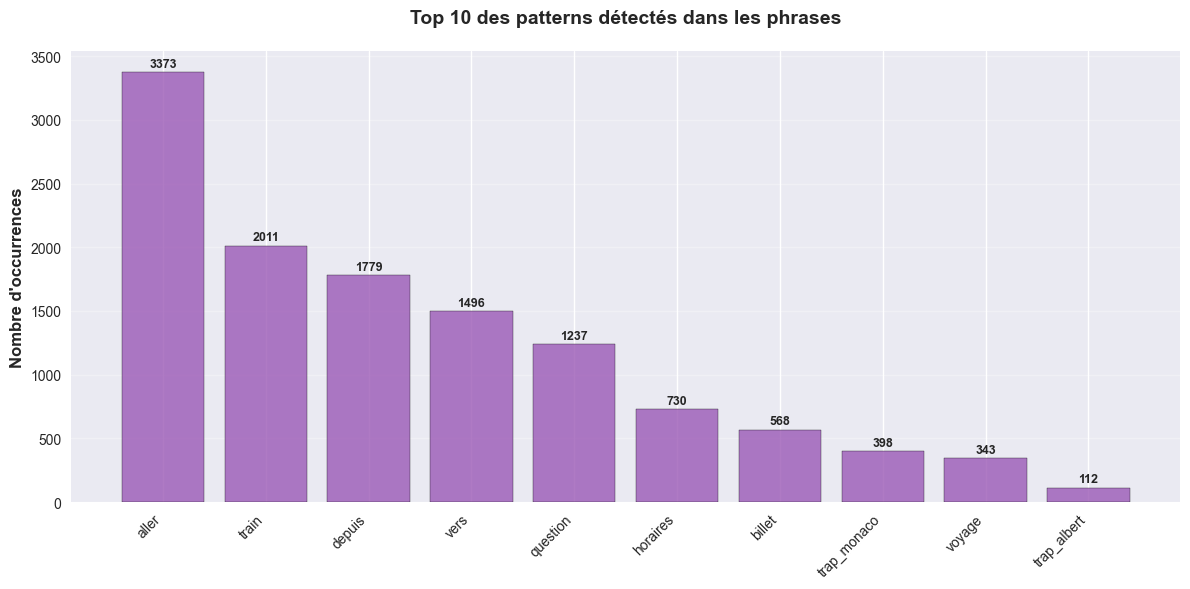

In [9]:
# Graphique des patterns
fig, ax = plt.subplots(1, 1, figsize=(12, 6))
patterns, counts = zip(*pattern_counts.most_common(10))
bars = ax.bar(range(len(patterns)), counts, color='#9b59b6', alpha=0.8, edgecolor='black')
ax.set_xticks(range(len(patterns)))
ax.set_xticklabels(patterns, rotation=45, ha='right', fontsize=10)
ax.set_ylabel('Nombre d\'occurrences', fontsize=12, fontweight='bold')
ax.set_title('Top 10 des patterns détectés dans les phrases', fontsize=14, fontweight='bold', pad=20)
ax.grid(axis='y', alpha=0.3)

# Ajoute les valeurs
for bar, count in zip(bars, counts):
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height + 20,
            str(count), ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

## 6. Analyse des pièges (traps)

In [10]:
# Détecte les phrases pièges
trap_keywords = ['monaco', 'albert', 'nancy', 'paris', 'florence', 'valerie']

def is_trap(phrase, depart, arrivee):
    """Détecte si une phrase est un piège"""
    phrase_lower = phrase.lower()
    
    # Piège: mentionne monaco/albert mais pas comme ville de trajet
    if 'monaco' in phrase_lower and 'boire' in phrase_lower:
        return True
    if 'albert' in phrase_lower and ('ami' in phrase_lower or 'voir' in phrase_lower):
        return True
    
    # Piège: utilise un prénom comme ville
    if depart == 'INVALID' and any(kw in phrase_lower for kw in trap_keywords):
        return True
    
    return False

df['is_trap'] = df.apply(lambda row: is_trap(row['phrase'], row['depart'], row['arrivee']), axis=1)

trap_count = df['is_trap'].sum()
print(f"\n⚠️  ANALYSE DES PIÈGES")
print(f"   {'-' * 50}")
print(f"   Phrases pièges détectées: {trap_count} ({trap_count/len(df)*100:.1f}%)")
print(f"   Phrases normales: {len(df) - trap_count} ({(len(df) - trap_count)/len(df)*100:.1f}%)")

# Affiche des exemples de pièges
trap_examples = df[df['is_trap']].head(10)
print(f"\n   Exemples de phrases pièges:")
for idx, row in trap_examples.iterrows():
    print(f"      - {row['phrase'][:70]}...")
    print(f"        → Départ: {row['depart']}, Arrivée: {row['arrivee']}")


⚠️  ANALYSE DES PIÈGES
   --------------------------------------------------
   Phrases pièges détectées: 1272 (11.6%)
   Phrases normales: 9728 (88.4%)

   Exemples de phrases pièges:
      - trains de valerie vers colombes...
        → Départ: INVALID, Arrivée: INVALID
      - depuis monaco je veux aller à monaco pour boire un monaco...
        → Départ: INVALID, Arrivée: INVALID
      - je veux aller voir monaco et boire un monaco...
        → Départ: INVALID, Arrivée: INVALID
      - depuis nancy aller à florence...
        → Départ: INVALID, Arrivée: INVALID
      - je dois rejoindre albert quelque part...
        → Départ: INVALID, Arrivée: INVALID
      - je veu aller de lyon à valerie boire un monaco...
        → Départ: INVALID, Arrivée: INVALID
      - trains de nancy vers nancy...
        → Départ: INVALID, Arrivée: INVALID
      - aller de florence a tours boire un monaco...
        → Départ: INVALID, Arrivée: INVALID
      - mon ami monaco veut aller à monaco voir florenc

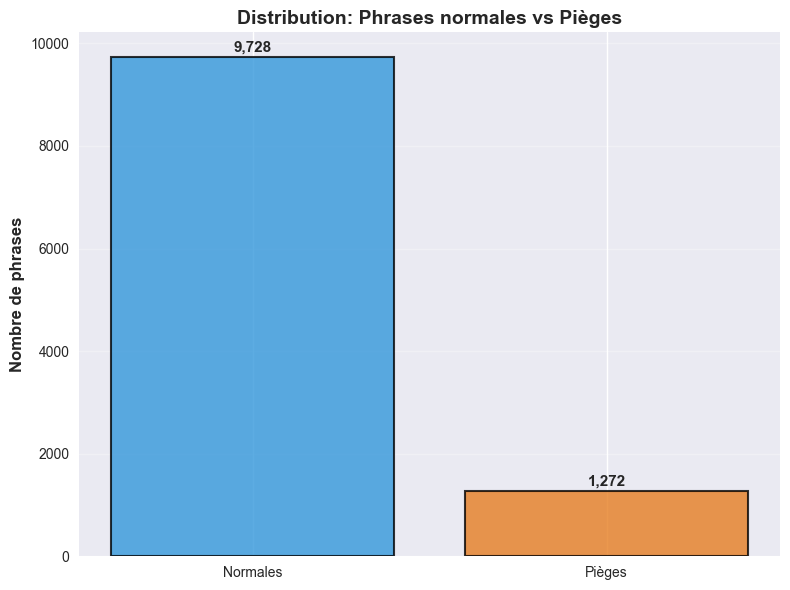

In [11]:
# Graphique pièges vs normales
fig, ax = plt.subplots(1, 1, figsize=(8, 6))
trap_counts = df['is_trap'].value_counts()
bars = ax.bar(['Normales', 'Pièges'], trap_counts.values, 
              color=['#3498db', '#e67e22'], alpha=0.8, edgecolor='black', linewidth=1.5)
ax.set_ylabel('Nombre de phrases', fontsize=12, fontweight='bold')
ax.set_title('Distribution: Phrases normales vs Pièges', fontsize=14, fontweight='bold')
ax.grid(axis='y', alpha=0.3)

# Ajoute les valeurs
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height + 50,
            f'{int(height):,}',
            ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

## 7. Distribution de la longueur des phrases

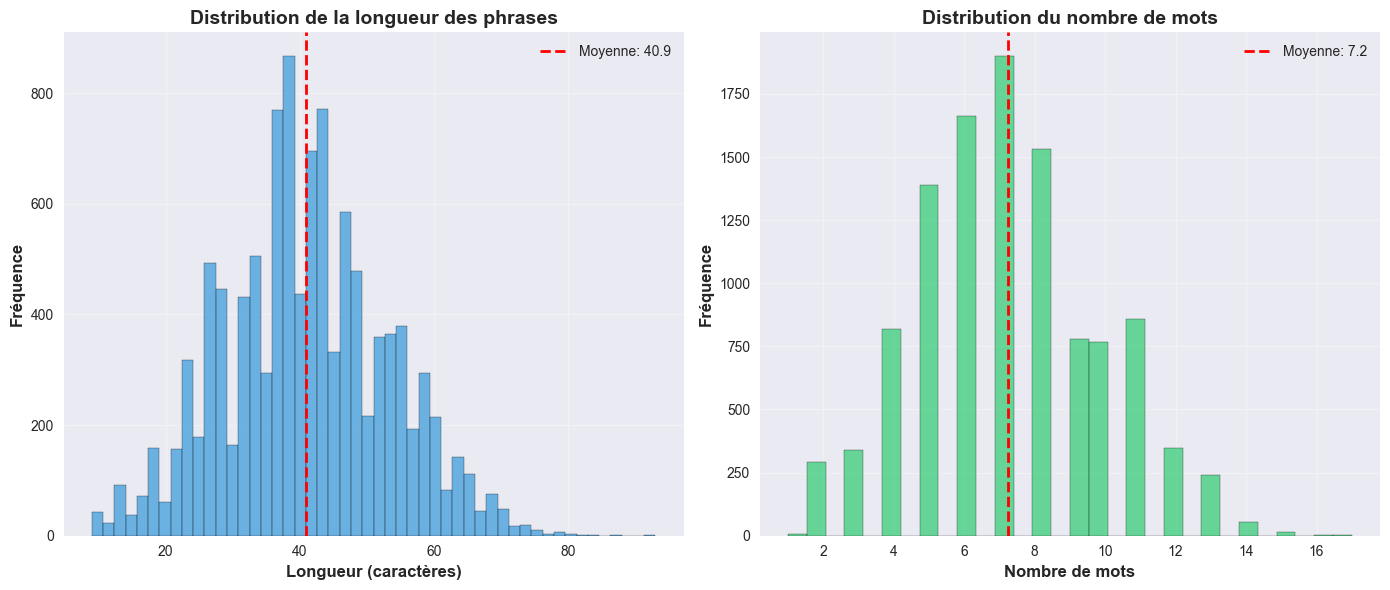

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Histogramme de la longueur des phrases
axes[0].hist(df['phrase_length'], bins=50, color='#3498db', alpha=0.7, edgecolor='black')
axes[0].axvline(df['phrase_length'].mean(), color='red', linestyle='--', linewidth=2, label=f'Moyenne: {df["phrase_length"].mean():.1f}')
axes[0].set_xlabel('Longueur (caractères)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Fréquence', fontsize=12, fontweight='bold')
axes[0].set_title('Distribution de la longueur des phrases', fontsize=14, fontweight='bold')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Histogramme du nombre de mots
axes[1].hist(df['word_count'], bins=30, color='#2ecc71', alpha=0.7, edgecolor='black')
axes[1].axvline(df['word_count'].mean(), color='red', linestyle='--', linewidth=2, label=f'Moyenne: {df["word_count"].mean():.1f}')
axes[1].set_xlabel('Nombre de mots', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Fréquence', fontsize=12, fontweight='bold')
axes[1].set_title('Distribution du nombre de mots', fontsize=14, fontweight='bold')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

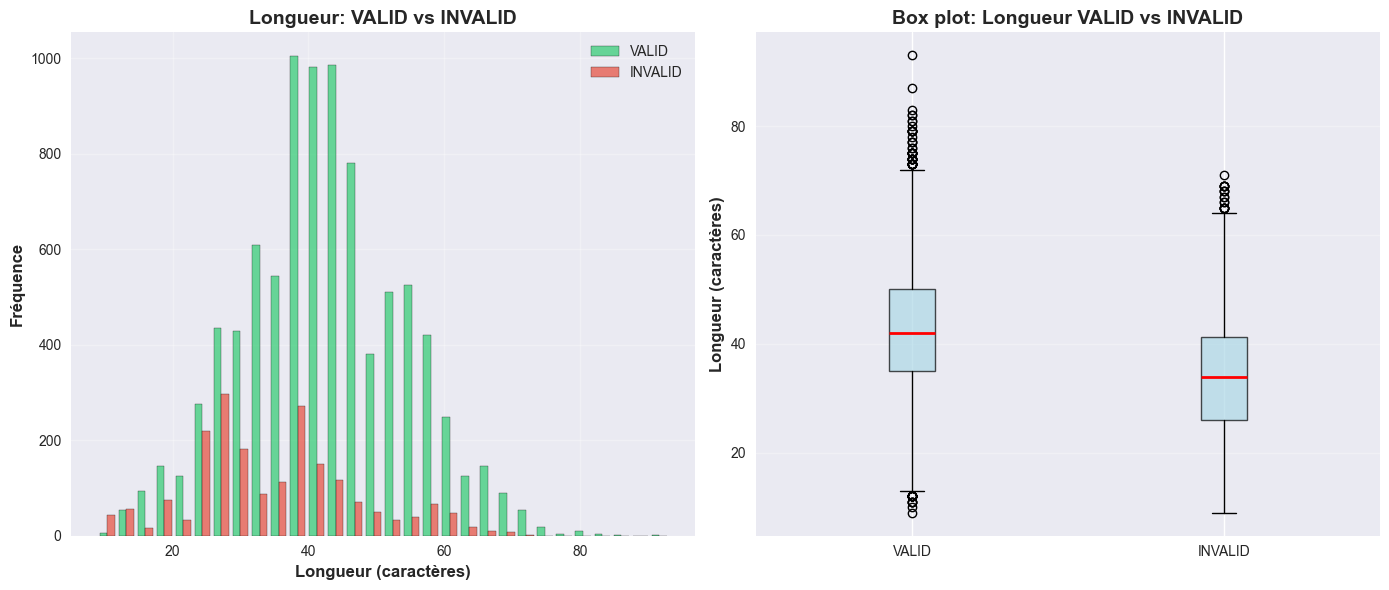


📊 Statistiques de longueur:
   VALID - Moyenne: 42.3, Médiane: 42.0
   INVALID - Moyenne: 34.7, Médiane: 34.0


In [13]:
# Comparaison longueur VALID vs INVALID
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

valid_lengths = df[df['is_valid']]['phrase_length']
invalid_lengths = df[~df['is_valid']]['phrase_length']

axes[0].hist([valid_lengths, invalid_lengths], bins=30, 
             label=['VALID', 'INVALID'], 
             color=['#2ecc71', '#e74c3c'], 
             alpha=0.7, edgecolor='black')
axes[0].set_xlabel('Longueur (caractères)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Fréquence', fontsize=12, fontweight='bold')
axes[0].set_title('Longueur: VALID vs INVALID', fontsize=14, fontweight='bold')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Box plot
data_to_plot = [valid_lengths, invalid_lengths]
bp = axes[1].boxplot(data_to_plot, labels=['VALID', 'INVALID'], 
                     patch_artist=True,
                     boxprops=dict(facecolor='lightblue', alpha=0.7),
                     medianprops=dict(color='red', linewidth=2))
axes[1].set_ylabel('Longueur (caractères)', fontsize=12, fontweight='bold')
axes[1].set_title('Box plot: Longueur VALID vs INVALID', fontsize=14, fontweight='bold')
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

print(f"\n📊 Statistiques de longueur:")
print(f"   VALID - Moyenne: {valid_lengths.mean():.1f}, Médiane: {valid_lengths.median():.1f}")
print(f"   INVALID - Moyenne: {invalid_lengths.mean():.1f}, Médiane: {invalid_lengths.median():.1f}")

## 8. Analyse des mots les plus fréquents

In [14]:
# Extrait tous les mots (sans stop words basiques)
stop_words = {'de', 'à', 'la', 'le', 'les', 'un', 'une', 'des', 'et', 'ou', 'pour', 'avec', 'dans', 'sur', 'par'}

all_words = []
for phrase in df['phrase']:
    words = phrase.lower().split()
    words = [w.strip('.,!?;:') for w in words if w.strip('.,!?;:') not in stop_words]
    all_words.extend(words)

word_counts = Counter(all_words)
top_words = word_counts.most_common(20)

print(f"\n📝 TOP 20 DES MOTS LES PLUS FRÉQUENTS")
print(f"   {'-' * 50}")
for i, (word, count) in enumerate(top_words, 1):
    print(f"   {i:2d}. {word:20s} : {count:5d} fois")


📝 TOP 20 DES MOTS LES PLUS FRÉQUENTS
   --------------------------------------------------
    1. aller                :  4430 fois
    2. je                   :  4174 fois
    3. a                    :  2968 fois
    4. trains               :  1993 fois
    5. depuis               :  1772 fois
    6. voudrais             :  1523 fois
    7. vers                 :  1243 fois
    8. comment              :  1221 fois
    9. rendre               :  1067 fois
   10. me                   :  1060 fois
   11. y                    :   982 fois
   12. mon                  :   868 fois
   13. en                   :   798 fois
   14. florence             :   761 fois
   15. paris                :   727 fois
   16. monaco               :   702 fois
   17. partant              :   644 fois
   18. voir                 :   642 fois
   19. albert               :   642 fois
   20. nancy                :   624 fois


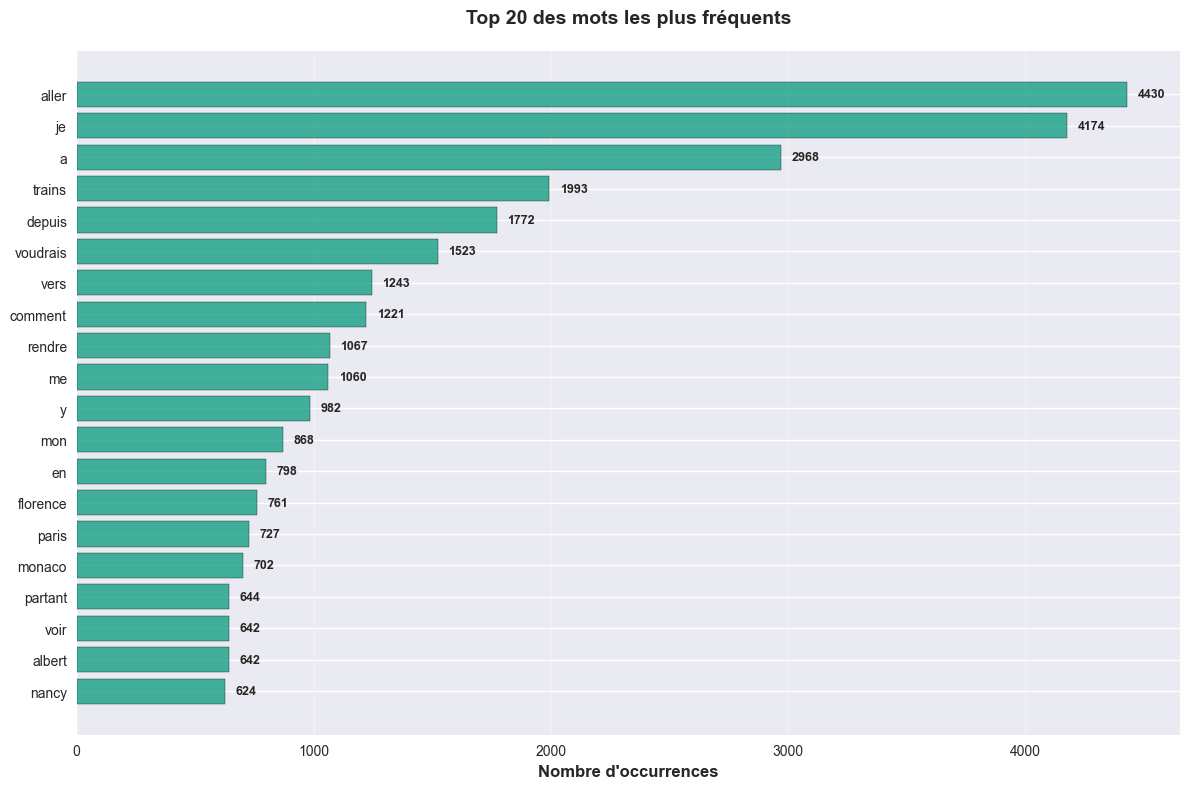

In [15]:
# Graphique des mots les plus fréquents
fig, ax = plt.subplots(1, 1, figsize=(12, 8))
words, counts = zip(*top_words)
bars = ax.barh(range(len(words)), counts, color='#16a085', alpha=0.8, edgecolor='black')
ax.set_yticks(range(len(words)))
ax.set_yticklabels(words, fontsize=10)
ax.set_xlabel('Nombre d\'occurrences', fontsize=12, fontweight='bold')
ax.set_title('Top 20 des mots les plus fréquents', fontsize=14, fontweight='bold', pad=20)
ax.invert_yaxis()
ax.grid(axis='x', alpha=0.3)

# Ajoute les valeurs
for i, (bar, count) in enumerate(zip(bars, counts)):
    ax.text(count + max(counts) * 0.01, bar.get_y() + bar.get_height()/2,
            str(count), va='center', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

## 9. Exemples de phrases par catégorie

In [16]:
print("\n" + "=" * 80)
print("📋 EXEMPLES DE PHRASES PAR CATÉGORIE")
print("=" * 80)

# Exemples VALID
valid_examples = df[df['is_valid']].head(5)
print("\n✅ Exemples VALID:")
for idx, row in valid_examples.iterrows():
    print(f"   - {row['phrase']}")
    print(f"     → {row['depart']} → {row['arrivee']}")

# Exemples INVALID
invalid_examples = df[~df['is_valid']].head(5)
print("\n❌ Exemples INVALID:")
for idx, row in invalid_examples.iterrows():
    print(f"   - {row['phrase']}")

# Exemples de pièges
trap_examples = df[df['is_trap']].head(5)
print("\n⚠️  Exemples de PIÈGES:")
for idx, row in trap_examples.iterrows():
    print(f"   - {row['phrase']}")
    print(f"     → {row['depart']} → {row['arrivee']}")


📋 EXEMPLES DE PHRASES PAR CATÉGORIE

✅ Exemples VALID:
   - y a-t-il des trains de limoges à villeurbanne
     → Limoges → Villeurbanne
   - Un voyage de amiens a vitry-sur-seine s'il vous plait
     → Amiens → Vitry-sur-Seine
   - je voudrai aller de orléans à villeurbanne
     → Orléans → Villeurbanne
   - de grenoble vers colombes
     → Grenoble → Colombes
   - je voudrais aller de rennes a strasbourg
     → Rennes → Strasbourg

❌ Exemples INVALID:
   - je cherche un restaurant
   - trains de valerie vers colombes
   - je voudrais réserver une chambre d'hôtel
   - depuis monaco je veux aller à monaco pour boire un monaco
   - je veux aller voir monaco et boire un monaco

⚠️  Exemples de PIÈGES:
   - trains de valerie vers colombes
     → INVALID → INVALID
   - depuis monaco je veux aller à monaco pour boire un monaco
     → INVALID → INVALID
   - je veux aller voir monaco et boire un monaco
     → INVALID → INVALID
   - depuis nancy aller à florence
     → INVALID → INVALID
   - j

## 10. Export des statistiques

In [17]:
# Crée un résumé des statistiques
stats = {
    'total_phrases': len(df),
    'valid_phrases': int(df['is_valid'].sum()),
    'invalid_phrases': int((~df['is_valid']).sum()),
    'trap_phrases': int(df['is_trap'].sum()),
    'unique_cities': len(city_counts),
    'total_city_occurrences': len(all_cities),
    'avg_phrase_length': float(df['phrase_length'].mean()),
    'avg_word_count': float(df['word_count'].mean()),
    'top_cities': dict(top_cities[:10]),
    'top_patterns': dict(pattern_counts.most_common(10))
}

# Sauvegarde en JSON
with open('dataset_statistics.json', 'w', encoding='utf-8') as f:
    json.dump(stats, f, indent=2, ensure_ascii=False)

print("✅ Statistiques sauvegardées dans 'dataset_statistics.json'")
print("\n📊 Résumé:")
print(json.dumps(stats, indent=2, ensure_ascii=False))

✅ Statistiques sauvegardées dans 'dataset_statistics.json'

📊 Résumé:
{
  "total_phrases": 11000,
  "valid_phrases": 9000,
  "invalid_phrases": 2000,
  "trap_phrases": 1272,
  "unique_cities": 62,
  "total_city_occurrences": 18000,
  "avg_phrase_length": 40.936181818181815,
  "avg_word_count": 7.249636363636363,
  "top_cities": {
    "Saint-Denis": 563,
    "Toulon": 314,
    "Reims": 313,
    "Angers": 313,
    "Vitry-sur-Seine": 310,
    "Villeurbanne": 306,
    "Tours": 305,
    "Amiens": 304,
    "Rennes": 304,
    "Lourdes": 302
  },
  "top_patterns": {
    "aller": 3373,
    "train": 2011,
    "depuis": 1779,
    "vers": 1496,
    "question": 1237,
    "horaires": 730,
    "billet": 568,
    "trap_monaco": 398,
    "voyage": 343,
    "trap_albert": 112
  }
}


## 11. Analyse des paires de villes

In [18]:
# Extrait les paires de villes (départ → arrivée)
city_pairs = []
for _, row in df[df['is_valid']].iterrows():
    if row['depart'] != 'INVALID' and row['arrivee'] != 'INVALID':
        city_pairs.append((row['depart'], row['arrivee']))

pair_counts = Counter(city_pairs)
top_pairs = pair_counts.most_common(15)

print(f"\n🗺️  TOP 15 DES PAIRES DE VILLES")
print(f"   {'-' * 50}")
for i, ((dep, arr), count) in enumerate(top_pairs, 1):
    print(f"   {i:2d}. {dep:20s} → {arr:20s} : {count:3d} fois")


🗺️  TOP 15 DES PAIRES DE VILLES
   --------------------------------------------------
    1. Port-Boulet          → Saint-Denis          :  11 fois
    2. Fort-de-France       → Saint-Denis          :  11 fois
    3. Argenteuil           → Saint-Denis          :  11 fois
    4. Lyon                 → Saint-Denis          :  10 fois
    5. Saint-Denis          → Brest                :  10 fois
    6. Nîmes                → Saint-Denis          :  10 fois
    7. Saint-Denis          → Amiens               :   9 fois
    8. Montpellier          → Nice                 :   9 fois
    9. Brest                → Saint-Denis          :   9 fois
   10. Tours                → Le Havre             :   9 fois
   11. Saint-Denis          → Colombes             :   9 fois
   12. Saint-Denis          → Mérignac             :   9 fois
   13. Saint-Denis          → Mulhouse             :   9 fois
   14. Tours                → Vitry-sur-Seine      :   9 fois
   15. Asnières-sur-Seine   → Perpignan      

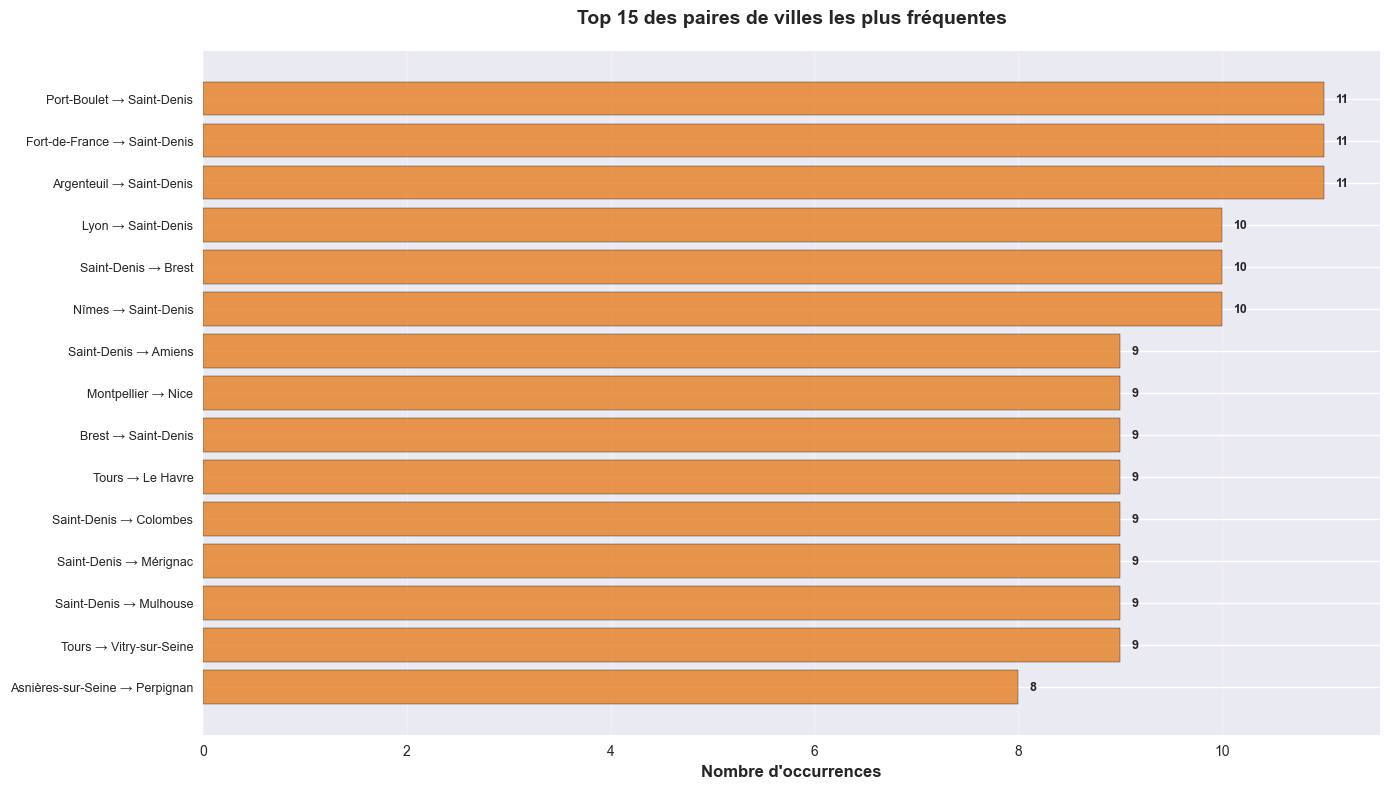

In [19]:
# Graphique des paires
fig, ax = plt.subplots(1, 1, figsize=(14, 8))
pairs_labels = [f"{dep} → {arr}" for (dep, arr), _ in top_pairs]
counts = [count for _, count in top_pairs]

bars = ax.barh(range(len(pairs_labels)), counts, color='#e67e22', alpha=0.8, edgecolor='black')
ax.set_yticks(range(len(pairs_labels)))
ax.set_yticklabels(pairs_labels, fontsize=9)
ax.set_xlabel('Nombre d\'occurrences', fontsize=12, fontweight='bold')
ax.set_title('Top 15 des paires de villes les plus fréquentes', fontsize=14, fontweight='bold', pad=20)
ax.invert_yaxis()
ax.grid(axis='x', alpha=0.3)

# Ajoute les valeurs
for i, (bar, count) in enumerate(zip(bars, counts)):
    ax.text(count + max(counts) * 0.01, bar.get_y() + bar.get_height()/2,
            str(count), va='center', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()